# Iris Species Prediction Using Decision Trees - Tensae Gonfa

This notebook uses a Decision Tree classification model
to predict Iris flower species based on flower measurements.

In [3]:
%pip install pandas scikit-learn matplotlib

Note: you may need to restart the kernel to use updated packages.


In [4]:
import pandas as pd

df = pd.read_csv("clean_iris.csv")

print(df.head())
print(df.columns)

   sepal_length  sepal_width  petal_length  petal_width      species
0           5.1          3.5           1.4          0.2  Iris-setosa
1           4.9          3.0           1.4          0.2  Iris-setosa
2           4.7          3.2           1.3          0.2  Iris-setosa
3           4.6          3.1           1.5          0.2  Iris-setosa
4           5.0          3.6           1.4          0.2  Iris-setosa
Index(['sepal_length', 'sepal_width', 'petal_length', 'petal_width',
       'species'],
      dtype='str')


In [5]:
# Select the features (flower measurements)
X = df[[
    "sepal_length",
    "sepal_width",
    "petal_length",
    "petal_width"
]]

# Select the target (flower species)
y = df["species"]

# Verify the features and target
print("Features (X):")
print(X.head())

print("\nTarget (y):")
print(y.head())

print("\nDataset shape:", X.shape)

Features (X):
   sepal_length  sepal_width  petal_length  petal_width
0           5.1          3.5           1.4          0.2
1           4.9          3.0           1.4          0.2
2           4.7          3.2           1.3          0.2
3           4.6          3.1           1.5          0.2
4           5.0          3.6           1.4          0.2

Target (y):
0    Iris-setosa
1    Iris-setosa
2    Iris-setosa
3    Iris-setosa
4    Iris-setosa
Name: species, dtype: str

Dataset shape: (147, 4)


In [6]:
from sklearn.model_selection import train_test_split

# Split the dataset: 80% training, 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Verify the split
print("Training records:", len(X_train))
print("Testing records:", len(X_test))

Training records: 117
Testing records: 30


In [7]:
from sklearn.tree import DecisionTreeClassifier

# Create the Decision Tree model
model = DecisionTreeClassifier(
    max_depth=3,
    random_state=42
)

# Train the model using the training dataset
model.fit(X_train, y_train)

# Verify the model was trained successfully
print("Decision Tree model trained successfully!")

print("Number of features:", model.n_features_in_)
print("Tree depth:", model.get_depth())
print("Number of leaf nodes:", model.get_n_leaves())

Decision Tree model trained successfully!
Number of features: 4
Tree depth: 3
Number of leaf nodes: 5


In [8]:
from sklearn.metrics import accuracy_score, classification_report

# Predict the species of the 30 test flowers
y_pred = model.predict(X_test)

# Calculate prediction accuracy
accuracy = accuracy_score(y_test, y_pred)

# Display results
print("Total flowers tested:", len(y_test))
print("Correct predictions:", sum(y_test == y_pred))
print("Incorrect predictions:", sum(y_test != y_pred))
print("Model accuracy:", round(accuracy * 100, 2), "%")

# Show performance for each Iris species
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Total flowers tested: 30
Correct predictions: 29
Incorrect predictions: 1
Model accuracy: 96.67 %

Classification Report:
                 precision    recall  f1-score   support

    Iris-setosa       1.00      1.00      1.00        10
Iris-versicolor       1.00      0.90      0.95        10
 Iris-virginica       0.91      1.00      0.95        10

       accuracy                           0.97        30
      macro avg       0.97      0.97      0.97        30
   weighted avg       0.97      0.97      0.97        30



### Confusion Matrix – Decision Tree Evaluation

The confusion matrix compares the actual Iris species with the species predicted by our Decision Tree model.

Correct predictions appear along the diagonal, while incorrect predictions appear outside the diagonal.

This visualization helps us identify which flower species the model classified correctly and where mistakes occurred.

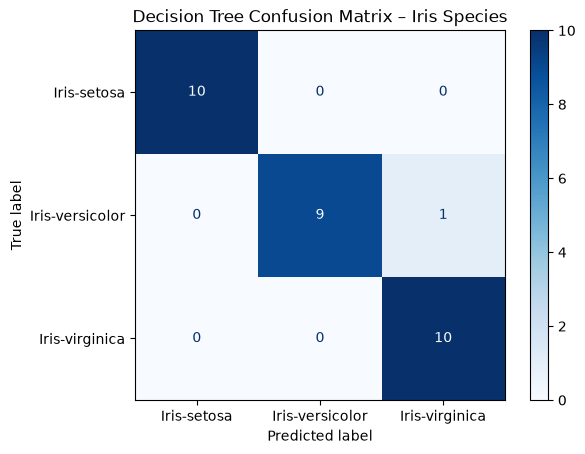

In [9]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Create confusion matrix using our trained Decision Tree
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=model.classes_,
    cmap="Blues",
    values_format="d"
)

# Add title
plt.title("Decision Tree Confusion Matrix – Iris Species")

# Save the visualization
plt.savefig("decision_tree_confusion_matrix.png",
            dpi=300, bbox_inches="tight")

plt.show()

### Confusion Matrix Results

The Decision Tree correctly classified 29 out of 30 flowers, achieving an accuracy of **96.67%**.

All Setosa and Virginica flowers were correctly classified. Of the 10 Versicolor flowers, 9 were correctly classified, while 1 was incorrectly predicted as Virginica.

Overall, the confusion matrix shows that the model performed well on the testing dataset, with only one misclassification.

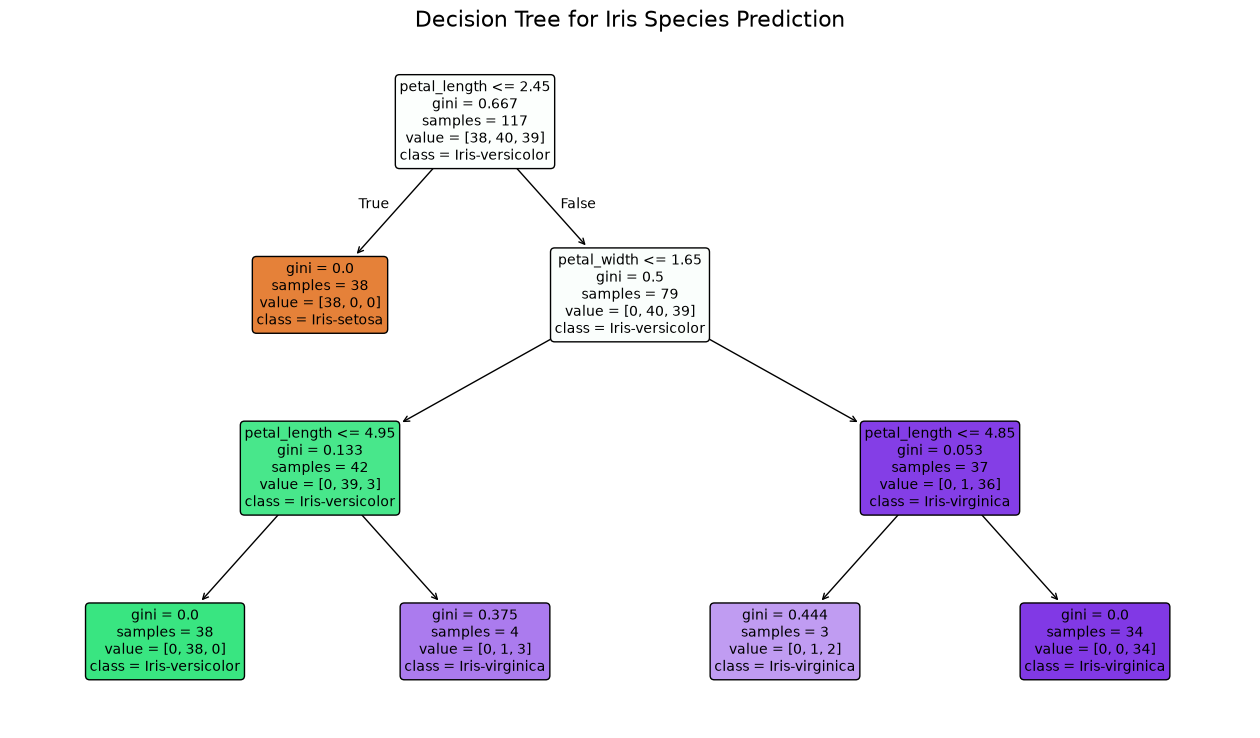

In [7]:
import matplotlib.pyplot as plt
from sklearn.tree import plot_tree

# Create the Decision Tree visualization
plt.figure(figsize=(16, 9))

plot_tree(
    model,
    feature_names=X.columns,
    class_names=model.classes_,
    filled=True,
    rounded=True,
    fontsize=10
)

plt.title("Decision Tree for Iris Species Prediction",
          fontsize=16)

# Save the graph for PowerPoint and GitHub
plt.savefig("decision_tree.png",
            dpi=300,
            bbox_inches="tight")

plt.show()

## Model Results and Findings

- Training dataset: 117 flowers
- Testing dataset: 30 flowers
- Correct predictions: 29 out of 30
- Model accuracy: 96.67%
- Most useful features selected by the tree:
  Petal length and petal width

The Decision Tree demonstrated that flower measurements
can be used to predict Iris species with high accuracy
on the test dataset.